# Simple Neural Network on Iris

**Objective:** Implement the core building blocks of a simple neural network and apply them to the Iris dataset.

**Dataset used:** `data/iris.csv`

**Main techniques used:** Sigmoid activation, feedforward propagation, cost function, gradient descent, neural network training


In [ ]:
#visualiser les donner avec hist()
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
np.random.seed(1)
#lire le dataset 
iris = pd.read_csv('data/iris.csv')
#melanger les lignes du dataset 
shuffled_rows  = np.random.permutation(iris.index)
iris = iris.loc[shuffled_rows, :]
print(iris.head())



     sepal_length  sepal_width  petal_length  petal_width     species
14            5.8          4.0           1.2          0.2      setosa
98            5.1          2.5           3.0          1.1  versicolor
75            6.6          3.0           4.4          1.4  versicolor
16            5.4          3.9           1.3          0.4      setosa
131           7.9          3.8           6.4          2.0   virginica


In [ ]:
   print(iris.species.unique())


['setosa' 'versicolor' 'virginica']


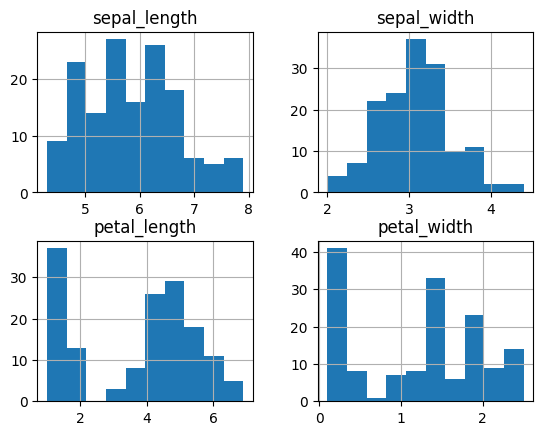

In [ ]:
iris.hist()
plt.show()


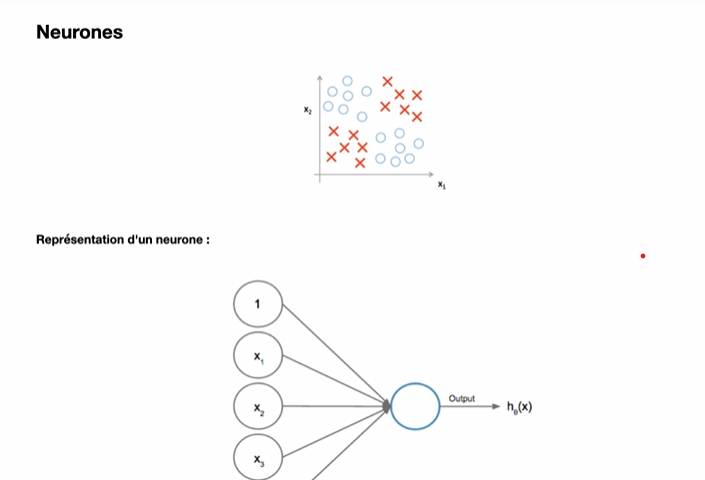


## Why a Neural Network Helps

The Iris classes are not always separable with a single linear boundary, so this notebook introduces a simple neural network approach.

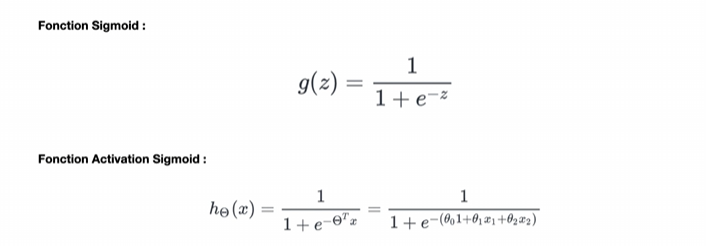

In [ ]:
z = np.asarray([[9,5,4]])
y = np.asarray([[-1 ,2,4]])
#np.dot() est utilsé pour la multiplication matricielle 
#z est lx3 et y est lx3 , z*y.T est ensuite 1x1
print(np.dot(z,y.T))


[[17]]


## Sigmoid Activation

This section implements the sigmoid activation function and applies it to a sample observation.


In [ ]:
##variables pour tester la fonction sigmoid_activation 
iris["ones"] = np.ones(iris.shape[0]) #on créé une colonne de 1 pour le biais 
#biais et les 4 caractéristique 
X = iris[["ones","sepal_length","sepal_width","petal_length","petal_width"]].values
#1 pour les iris de type versicolor et 0 pour toutes les autres 
y = (iris["species"] == "versicolor").values.astype(int)
#la premiere observation 
x0 =X[0]

#initialiser les thetas aleatoirement
np.random.seed(1)
thetas_init = np.random.normal(0,0.01, size=(5,1))



In [ ]:
def sigmoid_activation(x, theta):
    x=np.asarray(x) #converti x en tableauxx array
    theta = np.asarray(theta) #converti theta en tableauxx array
    return 1 / (1 + np.exp(-np.dot(theta.T,x)))
a1 = sigmoid_activation(x0,thetas_init)
print(a1)


[0.48712532]


## Cost Function

The cost function measures the gap between predicted values and target values.

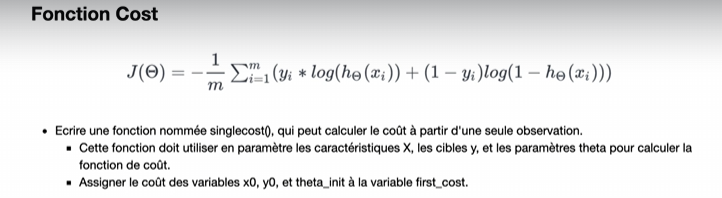


In [ ]:
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
y = (iris.species == 'versicolor' ).values.astype(int)

# Premières observations des caractéristiques et cible
x0 = X[0]
y0 = y[0]

# Initialiser les paramètres, nous avons 4 caractéristiques et un biais et une seule couche
np.random.seed(1)
theta_init = np.random.normal(0,0.01,size=(5,1))


In [ ]:
def singlecost(X,Y,theta):
    #appliquer la formule
    h = sigmoid_activation(X,theta)
    #prendre la moyenne negatif de la cible *log(activation) +(1-cible)*log(1-acti)
    cost =-np.mean(Y*np.log(h) + (1-Y)*np.log(1-h))
    
    return cost
f1_cost = singlecost(x0,y0,thetas_init)
print(f1_cost)


0.6677237568307639


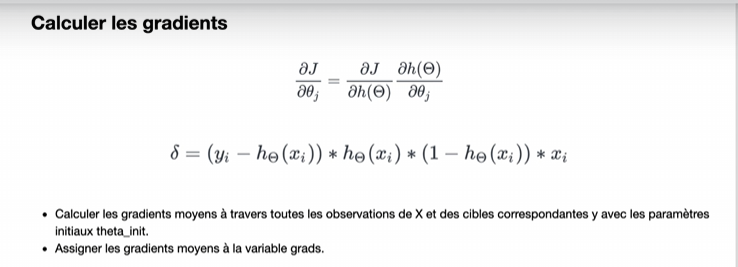


In [ ]:
# Initialiser les paramètres
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
y = (iris.species == 'versicolor' ) .values.astype(int)
np.random.seed(1)
theta_init = np.random.normal(0,0.01,size=(5,1))

# Stocker les mises à jours dans ce tableau array
grads = np.zeros(theta_init.shape)

# Nombre d'observations
n = X.shape[0]
print(n)


150


In [ ]:
for j , obs in enumerate(X):
    # Calculer l'activation pour l'observation j
    h = sigmoid_activation(obs, theta_init)
    #obtenir le delta
    delta = (y[j]-h)*h*(1-h)*obs
    #on somme ch&acun et on divise par n pour obtenir 
    grads += delta[:,np.newaxis]/X.shape[0]
print(grads)


[[-0.03753118]
 [-0.21073531]
 [-0.1387791 ]
 [-0.09740595]
 [-0.03372266]]


## Two-Layer Neural Network


## Gradient Descent Loop

Training updates the parameters until the cost improvement becomes small enough to stop.


In [ ]:
# Initialiser les paramètres
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
y = (iris.species == 'versicolor' ) .values.astype(int)
np.random.seed(1)
theta_init = np.random.normal(0,0.01,size=(5,1))


In [ ]:
#on fixe le taux d'apprentissage et le nombre d'itérations pour la descente de gradient
learning_rate = 0.1
maxepochs = 10000
#seuil de convergenc (prevcost - cost) > convergence_thres
convergence_thres = 0.00001
def learn(X,y,theta,learning_rate,maxepochs,convergence_thres):
    costs = []
    cost = singlecost(X,y,theta) #calcule lel cout initiale
    costprev = cost + 0.01+convergence_thres # on fixe un cout initial a ne pas depasser
    #boucle jusqua la convergence
    for counter in range(maxepochs): 
        grads = np.zeros(thta.shape)
        for j, obs in enumerate(X):
            h = sigmoid_activation(obs, theta) #calcul l'activation
            delta = (y[j]-h)*h*(1-h)*obs #calcul le delta
            grads += delta[:,np.newaxis]/X.shape[0] #calcul  moyennde de le gradient
        #mise a jour des parametres a partir des gradients
        theta += learning_rate*grads
        counter += 1 #compteur 
        costprev = cost #mettre a jour le cout precedent
        cost = singlecost(X,y,theta) #calculer le nouveau cout
        costs.append(cost) #stocker le cout pour le tracé
        #verifier la convergence
        if (np.abs(costprev - cost) < convergence_thres):
            print(f"Convergence atteinte après {counter} itérations.") #on verifie 
            break #lorsque aa converge par rapport au seuil definie on arrete
    plt.plot(costs)
    plt.xlabel('Itérations')
    plt.ylabel('Coût')
    plt.title('Évolution du coût au cours de l\'apprentissage')
    plt.show()
    return theta


In [ ]:
theta = learn(X,y,theta_init,learning_rate,maxepochs,convergence_thres)


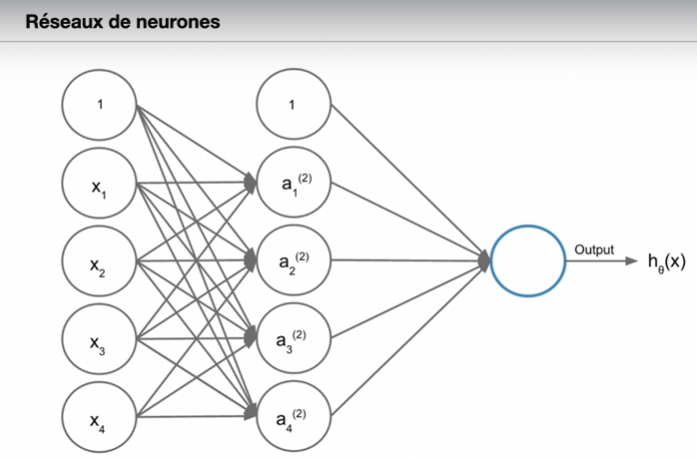


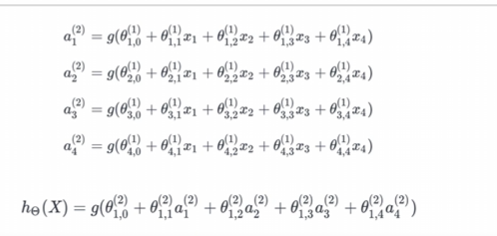


## Feedforward Propagation

This section builds the feedforward step for a two-layer neural network.


In [ ]:
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
np.random.seed(1)
theta0_init = np.random.normal(0,0.01,size=(5,4))
theta1_init = np.random.normal(0,0.01,size=(5,1))


In [ ]:
def feedforward (X ,theta0,theta1):
    #on nourrit le reseaux de neurones a partir de la premiere couche
    a1 = sigmoid_activation(X.T,theta0).T #activation de la
    #on ajoute une colonne de 1 pour le biais
    a1=np.column_stack([np.ones(a1.shape[0]),a1])
    #les unites d'activation sont ensuite imputés a la couche de sortie 
    out = sigmoid_activation(a1.T,theta1)
    return out
h = feedforward(X,theta0_init,theta1_init)


## Cost for the Two-Layer Network

The same learning objective is used to evaluate the network after adding the hidden layer.

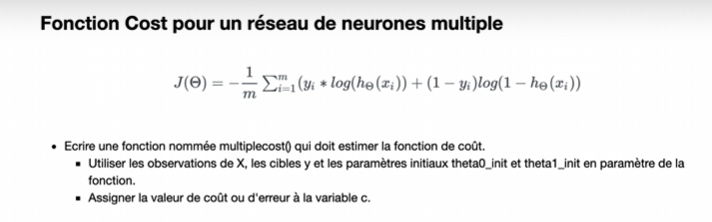


In [ ]:
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
y= (iris.species == 'versicolor' ) .values.astype(int)
np.random.seed(1)
theta0_init = np.random.normal(0,0.01,size=(5,4))
theta1_init = np.random.normal(0,0.01,size=(5,1))


In [ ]:
def multiplecost(X,Y,theta0,theta1):
    #nourir le reeaux de neurones 
    h = feedforward(X,theta0,theta1)
    #calculer le cout a partir de l'activation de la couche de sortie
    inner = y*np.log(h) + (1-y)*np.log(1-h)
    #retourner la negation de la l'erreur moyenne
    return -np.mean(inner)
c = multiplecost(X,y,theta0_init,theta1_init)


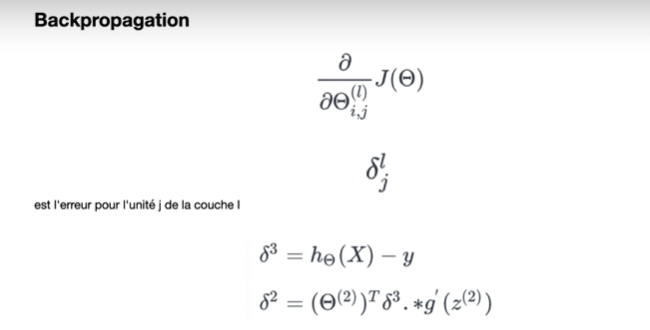


In [ ]:


def sigmoid_activation(x, theta):
    x = np.asarray(x) # convertit une entrée en tableau array
    theta = np.asarray(theta)
    return 1 / (1 + np.exp((-1)*np.dot(theta.T,x)))

# Utiliser une classe pour ce modèle, c'est une bonne pratique et permet de condenser le code
class NNet3:
    def __init__(self, learning_rate=0.5, maxepochs=1e4, 
                 convergence_thres=1e-5, hidden_layer=4):
        self.learning_rate = learning_rate
        self.maxepochs = int(maxepochs)
        self.convergence_thres = 1e-5
        self.hidden_layer = int(hidden_layer)
        
    def _multiplecost(self, X, y):
        # on nourrit le réseau de neurones
        _, l2 = self._feedforward(X) # on applique la fonction feedforward
        # on calcule l'erreur
        inner = y * np.log(l2) + (1-y) * np.log(1-l2)
        # négation de l'erreur moyenne
        return -np.mean(inner)
    
    def _feedforward(self, X):
        # données de la première couche
        l1 = sigmoid_activation(X.T, self.theta0).T
        # on ajoute une colonne de 1 pour le terme de biais
        l1 = np.column_stack([np.ones(l1.shape[0]), l1])
        # les unités d'activation sont ensuite imputées à la couche de soprtie
        l2 = sigmoid_activation(l1.T, self.theta1)
        return l1, l2
    
    def predict(self, X):
        _, y = self._feedforward(X)
        return y
    
    def learn(self, X, y):
        nobs, ncols = X.shape
        self.theta0 = np.random.normal(0,0.01,size=(ncols,self.hidden_layer))
        self.theta1 = np.random.normal(0,0.01,size=(self.hidden_layer+1,1))
        
        self.costs = []
        cost = self._multiplecost(X, y)
        self.costs.append(cost)
        costprev = cost + self.convergence_thres+1 # fixe un coût initial à ne pas dépasser
        counter = 0 # initialise un compteur
        
        # Boucle jusqu'à la convergence
        for counter in range(self.maxepochs):
            # on nourrit le réseau
            l1, l2 = self._feedforward(X)
            
            # on démarre la backpropagation
            # Calcul des gradients
            l2_delta = (y-l2) * l2 * (1-l2)
            l1_delta = l2_delta.T.dot(self.theta1.T) * l1 * (1-l1)
            
            # Update des paramètres par moyenne des gradients et en multipliant 
            # par le taux d'apprentissage
            self.theta1 += l1.T.dot(l2_delta.T) / nobs * self.learning_rate
            self.theta0 += X.T.dot(l1_delta)[:,1:] / nobs * self.learning_rate
            
            # Stockage des coûts et vérification de la convergence
            counter += 1 # décompte
            costprev = cost # Stockage du coût actuel dans prev cost
            cost = self._multiplecost(X, y) # on obtient le nouveau coût
            self.costs.append(cost)
            if np.abs(costprev-cost) < self.convergence_thres and counter > 500:
                break


In [ ]:
#on fixe le taux d'apprentissage
learning_rate = 0.5
#nombre d'iterations max pour le gradient descent
maxepochs = 10000
#seuil de convergenc (prevcost - cost) > convergence_thres
convergence_thres = 0.00001
#nombre de neurones ou unités d'activations par couche caché
hidden_units = 4
model = NNet3(learning_rate, maxepochs, convergence_thres, hidden_units)
#entrainment du modele
model.learn(X,y)
#tracer l'evolution des cout ou de l'erreur
plt.plot(model.costs)
plt.title('convergence de la fonction cost')
plt.ylabel('J')
plt.xlabel('iteration')
plt.show() 


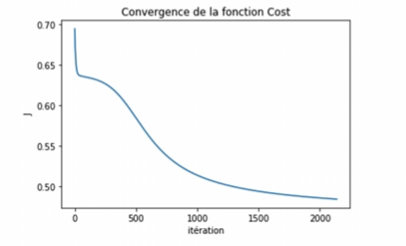


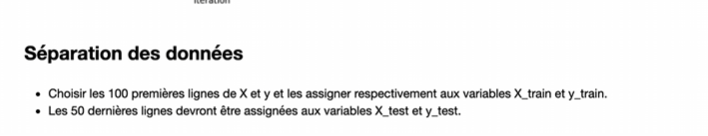


In [ ]:
X = iris[['ones', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width' ]].values
y= (iris.species == 'versicolor' ) .values.astype(int)


In [ ]:
x_train = X[:100]
y_train = y[:100]
x_test = X[-50:]
y_test = y[-50:]


In [ ]:
#Prédiction sur les fleurs d'iris


# fixer un taux d'apprentissage
learning_rate = 0.5
# Nombre maximum d'itérations pour le gradient descent
maxepochs = 10000
# seuil de convergence des coûts, par exemple (prevcost - cost) > convergence_thres
convergence_thres = 0.00001
# Nombre de neurones par couche cachee
hidden_units = 4

# Initialiser le modèle
model = NNet3(learning_rate=learning_rate, maxepochs=maxepochs,
convergence_thres=convergence_thres, hidden_layer=hidden_units)

# predict()



## Train and Evaluate the Model

The final step trains the neural network on the Iris training set and evaluates predictive performance on the test set.


In [ ]:
from sklearn.metrics import roc_auc_score

model.learn(x_train ,y_train)

yhat = model.predict(x_test)[0]
auc = roc_auc_score(y_test,yhat)


In [ ]:
auc
#0.6041


## Conclusion

**What was done:** Implemented key neural network steps and applied them to a classic Iris classification example.

**What was learned:** Activation functions, feedforward computation, and gradient-based learning are central to neural networks.

**Possible improvements:** Add clearer validation metrics, compare architectures, and use vectorized training throughout.
